F1 Uji (Random Forest): 0.9713
CI 95% Error Uji: -0.31% - 5.57%
Inference Time / 1000 baris: 0.2257 detik

CRITICAL ERROR (False Negatives): 3 pasien kanker divonis sehat.


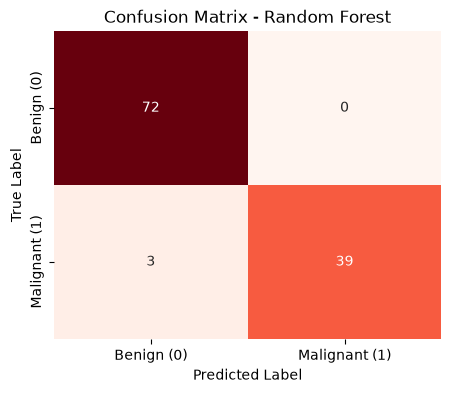

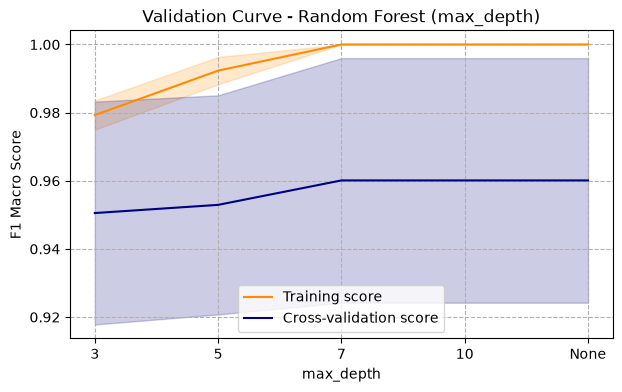

In [2]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, validation_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from scipy.stats import ttest_rel

# Load & Split Data
df = pd.read_csv('../data/breast_cancer.csv')
df = df.drop(['id', 'Unnamed: 32'], axis=1, errors='ignore')
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
X, y = df.drop('diagnosis', axis=1), df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Training model terbaik (Berdasarkan hasil NB 02)
rf = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42)
rf.fit(X_train, y_train)

# Inference Time per 1000 baris
start_inf = time.time()
y_pred_rf = rf.predict(X_test)
inf_time = ((time.time() - start_inf) / len(X_test)) * 1000

# Metrik Evaluasi & CI 95%
f1_uji = f1_score(y_test, y_pred_rf, average='macro')
error_uji = 1 - accuracy_score(y_test, y_pred_rf)
ci_margin = 1.96 * np.sqrt((error_uji * (1 - error_uji)) / len(y_test))

print(f"F1 Uji (Random Forest): {f1_uji:.4f}")
print(f"CI 95% Error Uji: {(error_uji - ci_margin)*100:.2f}% - {(error_uji + ci_margin)*100:.2f}%")
print(f"Inference Time / 1000 baris: {inf_time:.4f} detik\n")

# Analisis Error: Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)
tn, fp, fn, tp = cm.ravel()
print(f"CRITICAL ERROR (False Negatives): {fn} pasien kanker divonis sehat.")

fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False, 
            xticklabels=['Benign (0)', 'Malignant (1)'], yticklabels=['Benign (0)', 'Malignant (1)'])
plt.title('Confusion Matrix - Random Forest')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Kurva Validasi (Kedalaman Pohon)
param_range = [3, 5, 7, 10, None]
train_scores, test_scores = validation_curve(
    RandomForestClassifier(random_state=42), X_train, y_train, 
    param_name="max_depth", param_range=param_range, cv=5, scoring="f1_macro", n_jobs=-1)

# Hitung Rata-rata dan Simpangan Baku (Standard Deviation)
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(7,4))

# Plot Garis dan Area Bayangan untuk Training Score
plt.plot([str(p) for p in param_range], train_mean, label="Training score", color="darkorange")
plt.fill_between([str(p) for p in param_range], train_mean - train_std, train_mean + train_std, alpha=0.2, color="darkorange")

# Plot Garis dan Area Bayangan untuk Cross-validation Score
plt.plot([str(p) for p in param_range], test_mean, label="Cross-validation score", color="navy")
plt.fill_between([str(p) for p in param_range], test_mean - test_std, test_mean + test_std, alpha=0.2, color="navy")

plt.title("Validation Curve - Random Forest (max_depth)")
plt.xlabel("max_depth")
plt.ylabel("F1 Macro Score")
plt.legend(loc="best")
plt.grid(True, linestyle='--')
plt.show()